# 00 · Robot Plugging Sim: scene, assumptions, cameras

A MuJoCo stand-in for the WR1 data-center task: **a bimanual robot picks an RJ45 patch cable
off a shelf and plugs it into the lit port of a patch panel.** The goal is a controllable,
labelled data source for the lab's projects (WM failure monitors, latent steering, recovery),
with the same on-disk format as the real Bimanual Cable Manipulation data.

There is **no CAD, gripper geometry or kinematic model of WR1 yet**, so everything here is a
deliberate, strong placeholder assumption, collected in `plugsim/config.py`, one dataclass
field per assumption (see `ASSUMPTIONS.md`). Changing a number there changes the whole pipeline.

| Notebook | What |
|---|---|
| **00** | scene, assumptions, cameras, randomisation (this one) |
| 01 | insertion physics: jack, chamfer, latch, compliance, funnel maps, determinism |
| 02 | scripted expert demos (the "teleoperator") |
| 03 | failure injection + OOD shifts, outcome matrix |
| 04 | dataset generation (local and H100), format, counterfactual branching |

In [1]:
# Setup cell, inlined into every notebook by notebooks/build.py.
# Locally: finds the repo. On a Colab runtime (also VS Code connected to Colab), where the code is not
# on the VM: fetches it from (1) PLUGSIM_REPO (git URL, default: the public repo), (2) /content/RobotPluggingSim.zip, or
# (3) MyDrive/RobotPluggingSim (Drive), installs it, and keeps data/ + runs/ on Drive when mounted.
import os, sys, pathlib, subprocess
DEFAULT_REPO = "https://github.com/carlo-scr/RobotPluggingSim.git"
PLUGSIM_REPO = os.environ.get("PLUGSIM_REPO") or DEFAULT_REPO  # Colab: code is cloned from here
USE_DRIVE = os.environ.get("PLUGSIM_DRIVE", "1") == "1"  # set False if drive.mount hangs in your client
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
if IN_COLAB:
    # numpy's BLAS: one thread (the sim solves tiny systems; extra threads only add contention)
    os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
    os.environ.setdefault("MKL_NUM_THREADS", "1")
    os.environ.setdefault("MUJOCO_GL", "egl")
    os.environ.setdefault("PYOPENGL_PLATFORM", "egl")
    # Colab ships the NVIDIA driver but not its EGL vendor file, so EGL silently falls back to CPU
    # (software) rendering, ~100x slower. Register the NVIDIA EGL library (as in MuJoCo's Colab tutorial).
    _icd = pathlib.Path("/usr/share/glvnd/egl_vendor.d/10_nvidia.json")
    if subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0 and not _icd.exists():
        _icd.parent.mkdir(parents=True, exist_ok=True)
        _icd.write_text('{"file_format_version": "1.0.0", "ICD": {"library_path": "libEGL_nvidia.so.0"}}\n')
        print("registered the NVIDIA EGL vendor file (GPU rendering)")
    CODE = pathlib.Path("/content/RobotPluggingSim")
    DRIVE = pathlib.Path("/content/drive/MyDrive")
    if (CODE / ".git").exists():
        subprocess.run(["git", "-C", str(CODE), "pull", "-q"])  # pick up pushed changes
    if not (CODE / "plugsim").exists():
        if PLUGSIM_REPO:
            subprocess.run(["git", "clone", "-q", PLUGSIM_REPO, str(CODE)], check=True)
        elif pathlib.Path("/content/RobotPluggingSim.zip").exists():
            subprocess.run(["unzip", "-q", "-o", "/content/RobotPluggingSim.zip", "-d", "/content"], check=True)
    if USE_DRIVE and not DRIVE.exists():
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:  # e.g. not supported by the client; fine with PLUGSIM_REPO or the zip
            print("Drive not mounted:", e)
    if not (CODE / "plugsim").exists():
        if (DRIVE / "RobotPluggingSim").exists():
            subprocess.run(["rsync", "-a", "--exclude", ".venv", "--exclude", "data", "--exclude", "runs", "--exclude", "media",
                            f"{DRIVE}/RobotPluggingSim/", f"{CODE}/"], check=True)
        else:  # last resort: the public repo
            subprocess.run(["git", "clone", "-q", DEFAULT_REPO, str(CODE)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(CODE)], check=True)
    if DRIVE.exists():  # persist datasets and checkpoints across sessions / notebooks
        for d in ("data", "runs"):
            tgt = DRIVE / "plugsim_runs" / d
            tgt.mkdir(parents=True, exist_ok=True)
            link = CODE / d
            if not link.is_symlink():
                subprocess.run(["rm", "-rf", str(link)])
                link.symlink_to(tgt)
    else:
        print("WARNING: no Drive: data/ and runs/ live on the VM and are lost when the runtime stops")
    try:
        import torch
        if torch.cuda.is_available():
            os.environ.setdefault("PLUGSIM_SCALE", "a100")
    except ImportError:
        pass
    os.chdir(CODE)
ROOT = pathlib.Path.cwd()
while not (ROOT / "plugsim").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
if sys.platform.startswith("linux") and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")  # headless GPU nodes
print("ROOT:", ROOT, "| colab:", IN_COLAB, "| scale:", os.environ.get("PLUGSIM_SCALE", "local"))

ROOT: . | colab: False | scale: local


In [2]:
import os, sys, pathlib

import numpy as np
import matplotlib.pyplot as plt
import mujoco
from plugsim.config import EnvCfg
from plugsim.env import PlugEnv, state_names, action_names
from plugsim.scenario import sample_scenario, OOD_TYPES
from plugsim.tools import image_grid, plot_cable_layouts
print("mujoco", mujoco.__version__)

mujoco 3.15.0


## Key assumptions (defaults)
All lengths in metres. The real WR1 values should replace these once we have them.

In [3]:
cfg = EnvCfg()
rows = [
    ("Robot", "WR1 proxy: 2 x 7-DoF arms with Franka-Panda kinematics (primitives), parked base, torso + head"),
    ("Arm mounting", f"bases at x={cfg.arm.base_x}, y=±{cfg.arm.base_abs_y}, z={cfg.arm.base_z}"),
    ("Gripper", f"parallel jaw, force-controlled, {cfg.gripper.max_force} N, {2*cfg.gripper.max_opening*1000:.0f} mm stroke, {cfg.gripper.finger_thickness*1000:.0f} mm stepped fingers, pad μ={cfg.gripper.pad_friction}"),
    ("Control", f"{cfg.control_hz:.0f} Hz TCP-delta actions → DLS IK every {cfg.timestep*1000:.0f} ms physics step → joint PD + gravity comp."),
    ("Insertion mode", f"action bit 'compliant': gains {cfg.gripper.compliant_gains} at tool tip {cfg.gripper.tool_tip}"),
    ("Plug", f"RJ45 body {cfg.plug.body_w*1000:.1f}x{cfg.plug.body_h*1000:.1f}x{cfg.plug.body_len*1000:.0f} mm + boot, {cfg.plug.mass*1000:.0f} g, grasped {cfg.plug.grasp_from_tip*1000:.0f} mm behind tip"),
    ("Jack", f"clearance {cfg.port.clearance*1000:.1f} mm, chamfer {cfg.port.chamfer*1000:.1f} mm @45°, latch at {cfg.port.seat_depth*1000:.0f} mm depth (weld)"),
    ("Rack", f"19-inch rack, {cfg.rack.rows} x 1U {cfg.rack.cols}-port patch panels @ {cfg.rack.port_pitch*1000:.1f} mm (central |y|<={cfg.rack.active_half_width} m physical), switch, servers, cable managers; target port marked by a blue LED"),
    ("Occupancy", "0-50 % of the other ports already have colour-coded patch cables plugged in (nominal)"),
    ("Cable", f"Cat6, {cfg.cable.n_links*cfg.cable.link_len:.2f} m, {cfg.cable.n_links} capsule links + ball joints, far end plugged into a switch on the shelf"),
    ("Start state", "plug + cable lying on a shelf in front of the rack, random smooth layout"),
    ("Cameras", f"7 of WR1's 8 (head-back omitted); recorded by default: {', '.join(cfg.camera.record)} at {cfg.camera.width}x{cfg.camera.height}"),
]
for k, v in rows:
    print(f"{k:15s} {v}")

Robot           WR1 proxy: 2 x 7-DoF arms with Franka-Panda kinematics (primitives), parked base, torso + head
Arm mounting    bases at x=0.0, y=±0.26, z=0.8
Gripper         parallel jaw, force-controlled, 40.0 N, 80 mm stroke, 4 mm stepped fingers, pad μ=1.5
Control         20 Hz TCP-delta actions → DLS IK every 2 ms physics step → joint PD + gravity comp.
Insertion mode  action bit 'compliant': gains (1.0, 0.1, 0.1, 0.3, 0.3, 0.3) at tool tip (0.031, 0.0, 0.0035)
Plug            RJ45 body 11.7x8.0x21 mm + boot, 12 g, grasped 31 mm behind tip
Jack            clearance 1.0 mm, chamfer 1.5 mm @45°, latch at 15 mm depth (weld)
Rack            19-inch rack, 2 x 1U 24-port patch panels @ 18.5 mm (central |y|<=0.12 m physical), switch, servers, cable managers; target port marked by a blue LED
Occupancy       0-50 % of the other ports already have colour-coded patch cables plugged in (nominal)
Cable           Cat6, 0.70 m, 20 capsule links + ball joints, far end plugged into a switch on the 

In [4]:
env = PlugEnv(cfg)
m = env.model
print(f"nq={m.nq} nv={m.nv} nu={m.nu} bodies={m.nbody} geoms={m.ngeom}  physics dt={m.opt.timestep}s, "
      f"control dt={env.dt}s ({env.n_sub} substeps)")
print("observation.state:", len(state_names()), "dims, e.g.", state_names()[:3], "...", state_names()[-3:])
print("action:", len(action_names()), "dims:", action_names()[:8])

nq=144 nv=117 nu=16 bodies=102 geoms=830  physics dt=0.002s, control dt=0.05s (25 substeps)
observation.state: 44 dims, e.g. ['right.q1', 'right.q2', 'right.q3'] ... ['left.tcp_qy', 'left.tcp_qz', 'left.grip_width']
action: 16 dims: ['right.dx', 'right.dy', 'right.dz', 'right.drx', 'right.dry', 'right.drz', 'right.grip', 'right.compliant']


## The scene
A data-center aisle: the rack (patch panels with numbered labels, a top-of-rack switch, servers,
blanking panels and cable managers), neighbouring racks, a raised floor, a cable tray and ceiling
lights. Below: a third-person view (not a robot camera) and the seven robot cameras. The real WR1 has
head (front/back), chest (left/right) and two cameras per gripper. The lab's paper uses only the
gripper views because the cable is most visible there, so those four are recorded by default.
Their names ("front"/"rear" = the hand's ±x side) are placeholders until we know the real mounting.

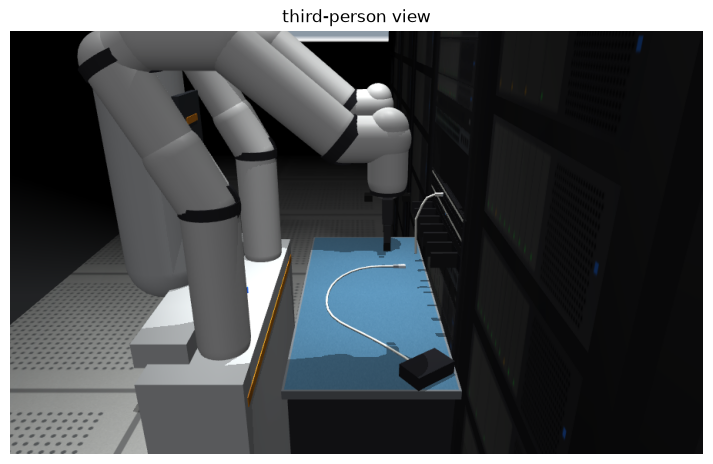

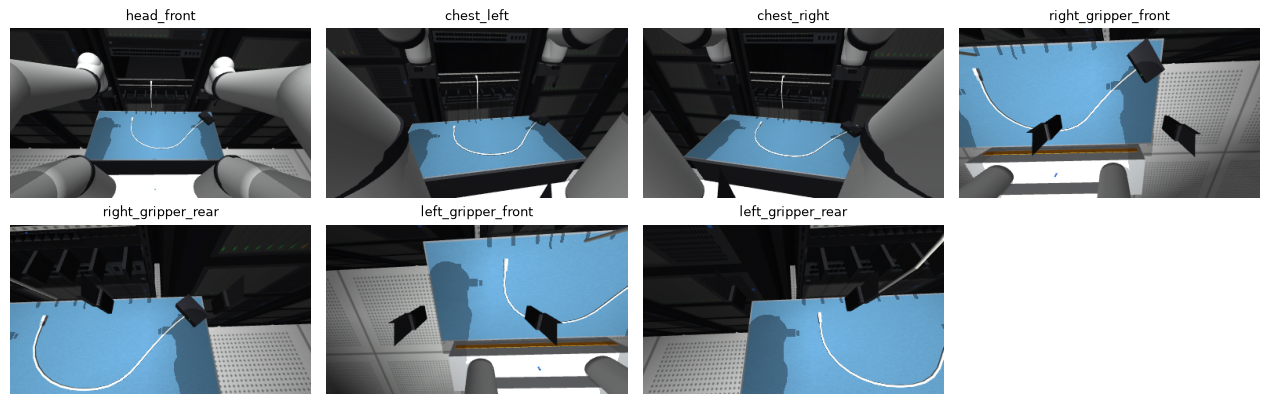

In [5]:
env.reset(seed=3)
plt.figure(figsize=(9, 5.5)); plt.imshow(env.render_free(width=900, height=550)); plt.axis("off"); plt.title("third-person view"); plt.show()
cams = cfg.camera.all_cameras
image_grid([env.render(c) for c in cams], titles=list(cams), cols=4); plt.show()

## Patch panel close-up and port occupancy
Ports are numbered on the label strips (1–24 top row, 25–48 bottom row). Occupied ports carry
drooping, colour-coded cables, so the target is often surrounded by neighbours that the thin
stepped fingers must clear.

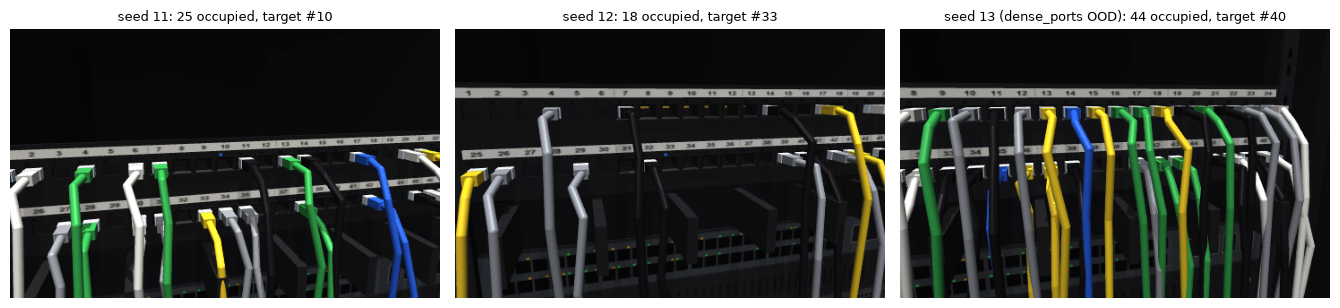

In [6]:
from plugsim.scenario import sample_scenario as _ss
imgs, titles = [], []
for seed, ood in ((11, []), (12, []), (13, ["dense_ports"])):
    sc = _ss(cfg, seed, ood=ood); env.reset(sc)
    pp = env.port_pose(sc.port_idx)[0]
    imgs.append(env.render_free(lookat=pp, distance=0.28, azimuth=-15, elevation=-12, width=480, height=300))
    titles.append(f"seed {seed}{' (dense_ports OOD)' if ood else ''}: {len(sc.occupied)} occupied, target #{sc.port_idx + 1}")
image_grid(imgs, titles, cols=3, scale=4.5); plt.show()

## Randomised start states
Each episode samples a cable layout: switch side, exit heading, and a smooth random curvature
profile with edge-steering, rejection-sampled so it stays on the shelf, doesn't self-intersect, and
leaves the plug reachable. It also samples a target port and visual/physical domain randomisation.
A `Scenario` (stored in every episode's `annotations.json`) fully determines the initial state.

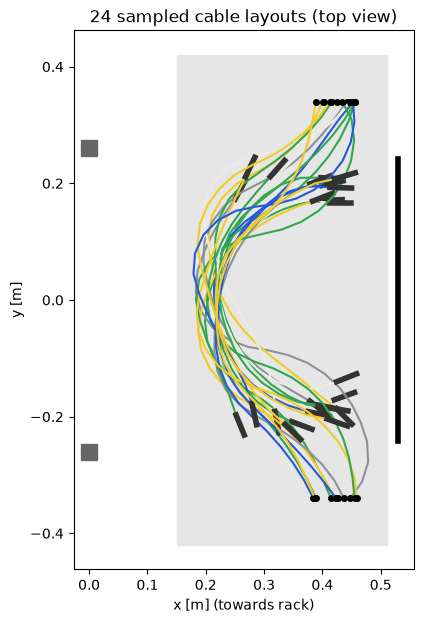

target ports: [0 0 0 0 0 0 1 0 0 2 0 0 0 1 0 0 2 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 2 0 1 3 2
 1 2 3 2 0 0 0 0 0 0 0]


In [7]:
scs = [sample_scenario(cfg, s) for s in range(24)]
fig, ax = plt.subplots(figsize=(6, 7))
plot_cable_layouts(cfg, scs, ax=ax); ax.set_title("24 sampled cable layouts (top view)"); plt.show()
print("target ports:", np.bincount([s.port_idx for s in scs], minlength=cfg.rack.n_ports))

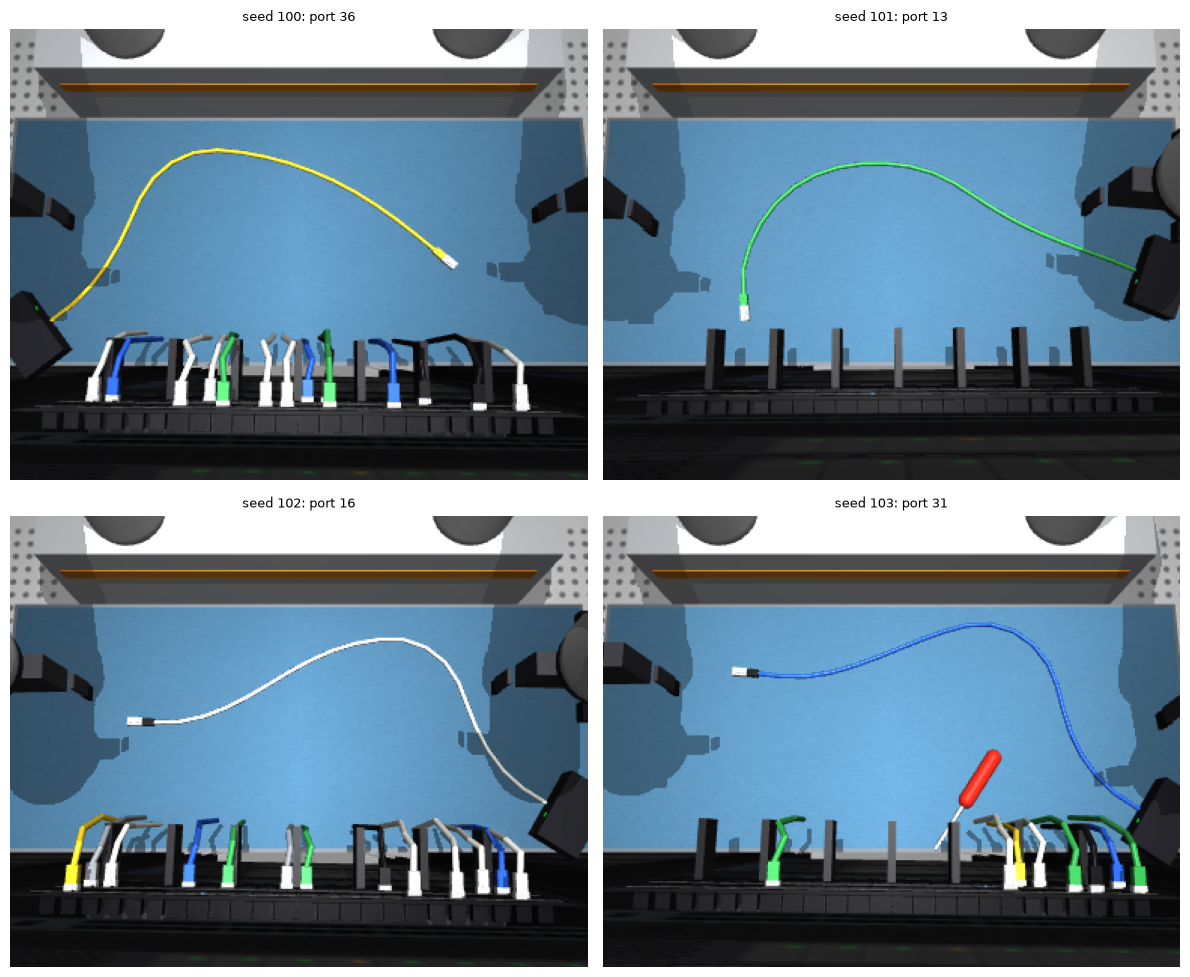

In [8]:
imgs, titles = [], []
for s in range(4):
    env.reset(seed=100 + s)
    imgs.append(env.render_free(lookat=(0.36, 0, 0.82), distance=0.75, azimuth=180, elevation=-80, width=384, height=300))
    titles.append(f"seed {100 + s}: port {env.scenario.port_idx}")
image_grid(imgs, titles, cols=2, scale=6); plt.show()

## Out-of-distribution shifts
Nominal domain randomisation defines "in distribution": cable colour from 5 and boot colour,
lighting ±20 %, rack pose ±1 cm/±1°, port occupancy, camera jitter ≈1.5 mm/0.7°, mild sensor noise,
occasional clutter, small friction/mass/stiffness ranges. Each of the 22 OOD types pushes one
factor **outside** those ranges, in four groups: lighting, appearance, sensor and physics. Below: the same scene through the active gripper's front camera (arm
held above the plug) and the head camera. `heavy_cable` and `slippery` are physical shifts and
not visible.

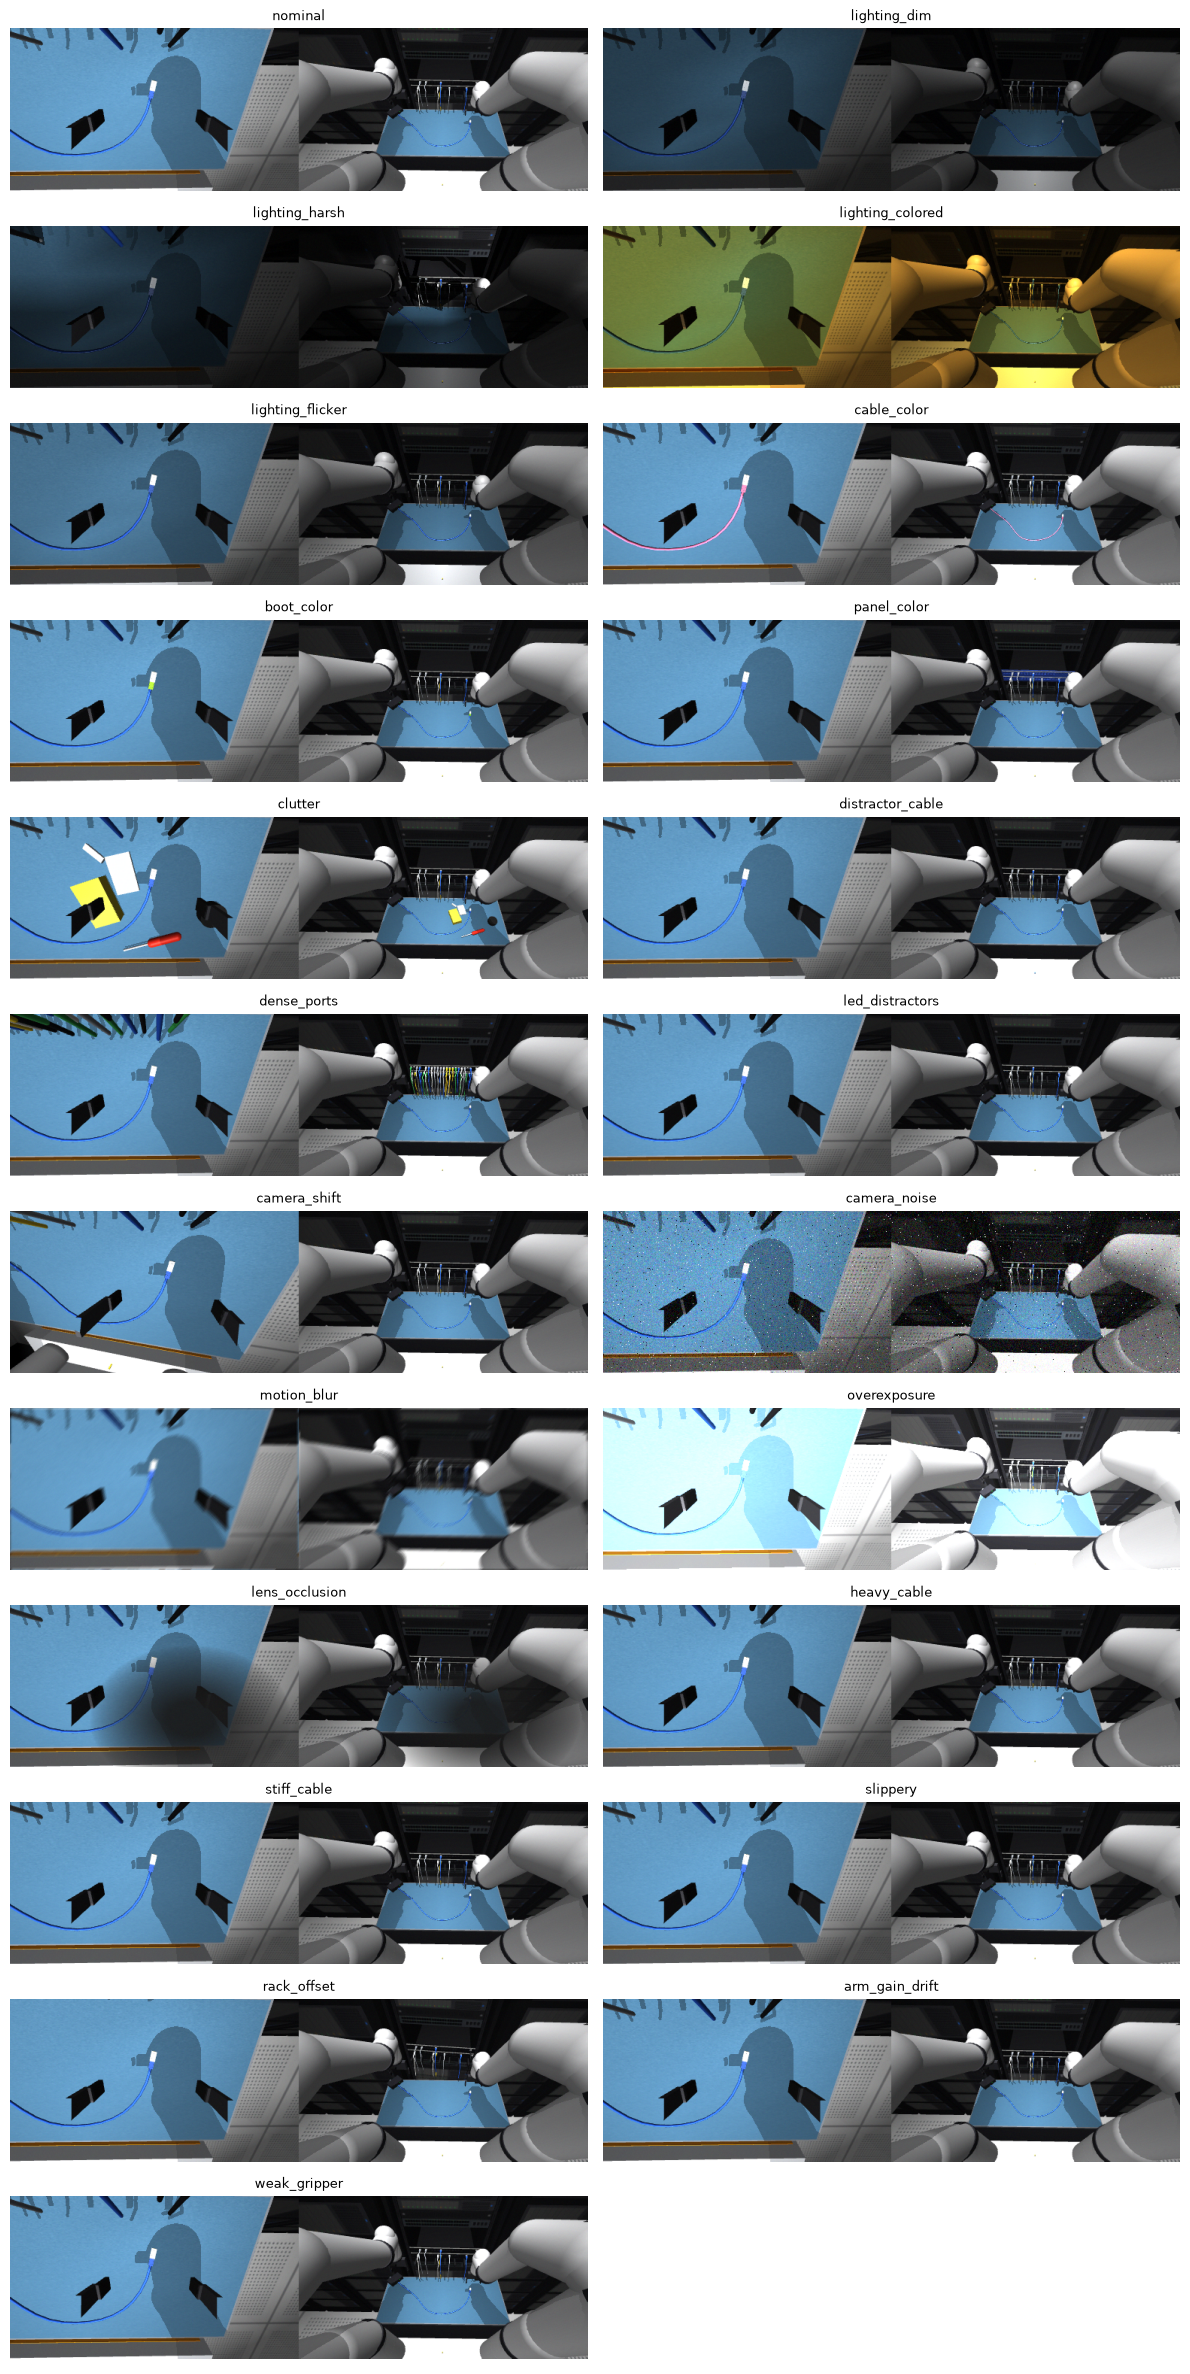

In [9]:
from plugsim.env import Q_DOWN
def gripper_view(sc):
    env.reset(sc)
    pr = env.privileged()
    tgt = pr["grasp_pos"] + np.array([0, 0, 0.12])
    side = "right" if pr["grasp_pos"][1] < 0 else "left"
    for _ in range(300):  # move the TCP above the plug (direct IK, no expert)
        env._physics_step(lambda: env._ik(side, tgt, Q_DOWN))
    mujoco.mj_forward(env.model, env.data)
    return np.concatenate([env.render(f"{side}_gripper_front"), env.render("head_front")], 1)
imgs = [gripper_view(sample_scenario(cfg, 7))]
titles = ["nominal"]
for o in OOD_TYPES:
    imgs.append(gripper_view(sample_scenario(cfg, 7, ood=[o]))); titles.append(o)
image_grid(imgs, titles, cols=2, scale=6); plt.show()